# 05 — Unsupervised learning, tuning and metrics

I cluster within-day normalised net-load shapes into operating regimes. Normalising within the day makes this shape clustering, not level clustering, and PCA before clustering removes the heavy correlation between the 24 hourly columns. I tune over algorithm, parameter and number of components, score with four metrics, name the regimes from their shapes, check them against weather, and test whether the label helps the notebook 04 forecast.

**Inputs:** `panel.parquet`

**Outputs:** ledger block `results.json:nb05` (including `regime_names`); daily regime labels in `data/processed/unsupervised`; figures `05_algorithm_diagnostics.png`, `05_cluster_metrics.png`, `05_centroids.png`, `05_regime_weather.png`, `05_regime_vs_zone.png`, `05_downstream_utility.png`.


### 5.1 — Build the daily shape matrix

One row per zone-day on local time, 24 columns, each day scaled to its own range, so every row runs from 0 to 1. This choice defines what "similar" means.


In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as cfg
from src import results as R

pd.set_option("display.width", 140, "display.max_columns", 50)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI
np.random.seed(cfg.SEED)

from src import features as P

df = pd.read_parquet(cfg.PANEL)
shapes = P.daily_shape_matrix(df)
# Hours are LOCAL per zone (cfg.ZONE_TZ). A local day is dropped when any of its 24
# hours is missing -- incomplete days, and the spring-forward DST day (23 local
# hours). The autumn fall-back day (25 local hours) is KEPT: pivot_table averages
# its repeated hour. n_possible counts UTC dates while the matrix is keyed by local
# dates, so the printed figure is a net shortfall, not an exact count of dropped days.
n_possible = df.groupby(cfg.GROUP_COL)[cfg.TIME_COL].apply(
    lambda s: s.dt.normalize().nunique()).sum()
print(f"shape matrix {shapes.shape[0]:,} zone-days x {shapes.shape[1]} local hours")
print(f"{n_possible - len(shapes):,} fewer zone-days than the {n_possible:,} UTC-dated ones "
      f"({100 * (n_possible - len(shapes)) / n_possible:.2f}%): incomplete and spring-forward DST local days")
assert np.allclose(shapes.max(axis=1), 1) and np.allclose(shapes.min(axis=1), 0)
shapes.head()

shape matrix 13,069 zone-days x 24 local hours
83 fewer zone-days than the 13,152 UTC-dated ones (0.63%): incomplete and spring-forward DST local days


0         1         2         3         4         5         6         7         8         9         10        11  \
zone date                                                                                                                                 
BPAT 2019-01-01  0.228096  0.092686  0.019551  0.005069  0.000000  0.073860  0.268646  0.484432  0.633599  0.728458  0.828385  0.809558   
     2019-01-02  0.076279  0.053792  0.041887  0.062610  0.136243  0.309965  0.553351  0.866843  1.000000  0.969136  0.862434  0.731041   
     2019-01-03  0.271739  0.128623  0.045290  0.030797  0.000000  0.082729  0.333333  0.668478  0.853865  0.893720  0.864130  0.755435   
     2019-01-04  0.344778  0.210300  0.120887  0.024320  0.000000  0.082260  0.311159  0.540057  0.668455  0.804363  0.802575  0.804006   
     2019-01-05  0.321224  0.119822  0.037604  0.000000  0.056087  0.131931  0.300191  0.529637  0.743786  0.900574  1.000000  0.964308   

                       12        13        14        15        16        17        18        19        20        21        22        23  
zone date                                                                                                                                
BPAT 2019-01-01  0.694424  0.531499  0.364953  0.334540  0.297610  0.611875  0.916003  1.000000  0.919623  0.845040  0.614048  0.308472  
     2019-01-02  0.623016  0.548942  0.474868  0.453704  0.455467  0.611993  0.755732  0.731922  0.674162  0.569665  0.304233  0.000000  
     2019-01-03  0.687802  0.603261  0.577295  0.616546  0.679952  0.871377  1.000000  0.961353  0.906401  0.759662  0.540459  0.236715  
     2019-01-04  0.780758  0.790415  0.755722  0.733548  0.762876  0.898069  1.000000  0.977825  0.919170  0.873391  0.783619  0.647711  
     2019-01-05  0.942001  0.918419  0.803059  0.750159  0.717655  0.908859  0.936902  0.782027  0.644997  0.347355  0.201402  0.067559

### 5.2 — Tune over three axes

Number of principal components x algorithm (k-means, Ward, DBSCAN) x algorithm parameter. DBSCAN's `eps` is read from the k-distance curve and Ward's cut from the dendrogram.


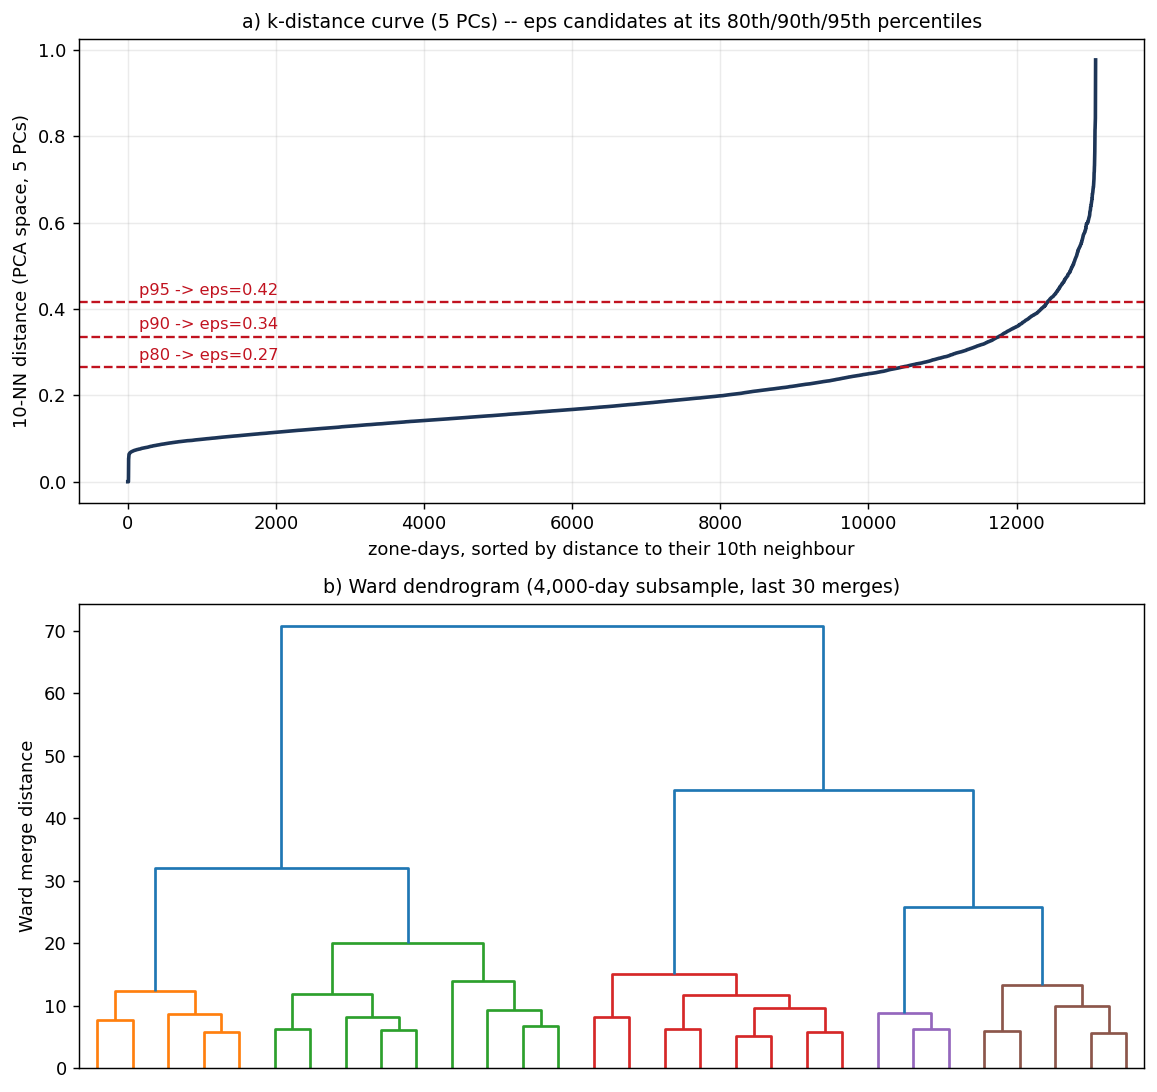

Ward: the last 8 merge heights, largest first
   70.7  44.5  32.0  25.7  20.1  15.0  14.0  13.2
   biggest drop is after merge 1 -> suggests k = 2


,n_clusters,silhouette,calinski_harabasz,davies_bouldin,ari_stability,noise_fraction,n_components,algorithm,param,seconds
13,3,0.429,9272.608,1.010,0.996,0.0,5,kmeans,3.0,0.7
26,3,0.411,8448.852,1.066,0.995,0.0,8,kmeans,3.0,0.8
0,3,0.473,12389.981,0.862,0.994,0.0,3,kmeans,3.0,0.8
2,4,0.401,12243.879,0.930,0.992,0.0,3,kmeans,4.0,0.7
28,4,0.316,7660.754,1.186,0.990,0.0,8,kmeans,4.0,0.7
15,4,0.339,8571.198,1.108,0.990,0.0,5,kmeans,4.0,0.8
17,5,0.325,8039.031,1.066,0.984,0.0,5,kmeans,5.0,1.0
30,5,0.300,7069.510,1.144,0.983,0.0,8,kmeans,5.0,0.8
4,5,0.377,11415.577,0.891,0.977,0.0,3,kmeans,5.0,1.0
19,6,0.301,7264.743,1.183,0.962,0.0,5,kmeans,6.0,1.2



best ARI stability per algorithm:
  dbscan   ari=0.920  sil=0.160  clusters=4  noise=6.9%  (8 PCs, param=0.415)
  kmeans   ari=0.996  sil=0.429  clusters=3  noise=0.0%  (5 PCs, param=3.0)
  ward     ari=0.666  sil=0.383  clusters=3  noise=0.0%  (8 PCs, param=3.0)
[results read-only] nb05: 5 key(s) verified against the ledger, nothing written


In [2]:
# WHAT: tune over all three axes -- n_components x algorithm x algorithm parameter --
#       with the two diagnostic figures each alternative algorithm needs to be
#       chosen honestly: a dendrogram for Ward, a k-distance plot for DBSCAN.
# WHY:  "we ran k-means with k=4" is not tuning. DBSCAN in particular cannot be
#       grid-searched blind -- eps has to come from the data's own distance
#       distribution, which is what the k-distance curve shows. The grid takes its
#       80th/90th/95th percentiles on 5 PCs and reuses those radii at 3 and 8 PCs.
import time

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.neighbors import NearestNeighbors

Z5 = P.make_clustering_pipeline(n_components=5).named_steps["pca"].fit_transform(shapes)

# --- the k-distance curve that sets eps ---------------------------------------
# DBSCAN's eps is a RADIUS in the PCA space, so it cannot be guessed. Sort every
# point's distance to its min_samples-th neighbour: the knee is where points stop
# being in dense neighbourhoods and start being outliers.
MIN_SAMPLES = 10
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES)
                .fit(Z5).kneighbors(Z5)[0][:, -1])
knee_pcts = (80, 90, 95)
eps_grid = [float(np.percentile(kdist, p)) for p in knee_pcts]

fig, axes = plt.subplots(2, 1, figsize=(9.0, 8.5))
ax = axes[0]
ax.plot(np.arange(len(kdist)), kdist, lw=2, color="#1d3557")
for p, e in zip(knee_pcts, eps_grid):
    ax.axhline(e, ls="--", lw=1.3, color="#c1121f")
    ax.annotate(f"p{p} -> eps={e:.2f}", (0, e), xytext=(6, 4),
                textcoords="offset points", fontsize=9, color="#c1121f")
ax.set_xlabel(f"zone-days, sorted by distance to their {MIN_SAMPLES}th neighbour")
ax.set_ylabel(f"{MIN_SAMPLES}-NN distance (PCA space, 5 PCs)")
ax.set_title("a) k-distance curve (5 PCs) -- eps candidates at its 80th/90th/95th percentiles", fontsize=10.5)
ax.grid(alpha=0.25)

# --- the Ward dendrogram -------------------------------------------------------
# Truncated to the last 30 merges: 13k leaves is an ink blot. The y-axis is the
# Ward merge distance, sqrt(2 x the within-cluster sum-of-squares increase the merge
# costs), so a LONG vertical edge means the merge below it joined two genuinely
# separate groups. The colours are cut at the 4th-largest merge height and are a
# visual aid, not the chosen partition.
rs = np.random.RandomState(cfg.SEED)
sub = rs.choice(len(Z5), 4000, replace=False)
link = linkage(Z5[sub], method="ward")
ax = axes[1]
dendrogram(link, truncate_mode="lastp", p=30, ax=ax, no_labels=True,
           color_threshold=link[-4, 2])
ax.set_title("b) Ward dendrogram (4,000-day subsample, last 30 merges)", fontsize=10.5)
ax.set_ylabel("Ward merge distance")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "05_algorithm_diagnostics.png", bbox_inches="tight")
plt.show()

merge_heights = link[-8:, 2][::-1]
print("Ward: the last 8 merge heights, largest first")
print("   " + "  ".join(f"{h:,.1f}" for h in merge_heights))
gaps = merge_heights[:-1] - merge_heights[1:]
print(f"   biggest drop is after merge {int(np.argmax(gaps)) + 1} "
      f"-> suggests k = {int(np.argmax(gaps)) + 2}")

# --- the full grid -------------------------------------------------------------
rows = []
for n_comp in (3, 5, 8):
    for k in (3, 4, 5, 6, 7):
        for algo in ("kmeans", "ward"):
            t0 = time.time()
            pipe = P.make_clustering_pipeline(n_components=n_comp, algorithm=algo, k=k)
            s = P.score_clustering(pipe, shapes)
            rows.append({**s, "n_components": n_comp, "algorithm": algo,
                         "param": float(k), "seconds": round(time.time() - t0, 1)})
    for eps in eps_grid:
        t0 = time.time()
        pipe = P.make_clustering_pipeline(n_components=n_comp, algorithm="dbscan",
                                          eps=eps, min_samples=MIN_SAMPLES)
        s = P.score_clustering(pipe, shapes)
        rows.append({**s, "n_components": n_comp, "algorithm": "dbscan",
                     "param": round(eps, 3), "seconds": round(time.time() - t0, 1)})

grid = pd.DataFrame(rows)
display(grid.sort_values("ari_stability", ascending=False).head(12).round(3))

print("\nbest ARI stability per algorithm:")
for algo, sub_g in grid.groupby("algorithm"):
    b = sub_g.sort_values("ari_stability", ascending=False).iloc[0]
    print(f"  {algo:8s} ari={b['ari_stability']:.3f}  sil={b['silhouette']:.3f}  "
          f"clusters={int(b['n_clusters'])}  noise={b['noise_fraction']:.1%}  "
          f"({int(b['n_components'])} PCs, param={b['param']})")

R.save("nb05", {
    "grid": grid.round(4).to_dict("records"),
    "eps_grid": [round(e, 4) for e in eps_grid],
    "min_samples": MIN_SAMPLES,
    "ward_merge_heights": [float(h) for h in merge_heights],
    "ward_suggested_k": int(np.argmax(gaps)) + 2,
});


**What this shows:** Panel (a) is the k-distance curve (each day's distance to its 10th nearest neighbour in 5-PC space, sorted) with the percentile cuts used as DBSCAN's `eps`. Panel (b) is the Ward dendrogram over the last 30 merges of a 4,000-day subsample.

**What I see:** The `eps` candidates are 0.266, 0.336 and 0.415 (80th, 90th, 95th percentiles), all below the curve's sharp final turn. The same radii are reused at 3 and 8 PCs, where distances run on a different scale. Ward's largest merge heights are 70.7, 44.5, 32.0, 25.7, and the biggest gap suggests k = 2.

**What it means:** `eps` is a radius in this PCA space, so its useful range comes from the data's own distances, not a blind grid. The dendrogram points to k = 2, one fewer than the k = 3 the metrics pick in §5.3; geometry alone does not settle the count.

**What I do:** Choose the winner on ARI stability, not silhouette. Silhouette rewards tidy partitions; ARI stability asks whether the same partition reappears under an 80% resample.

### 5.3 — The four metrics, reported together

Silhouette, Calinski-Harabasz, Davies-Bouldin and ARI stability, plotted against the number of clusters each run actually produced. ARI stability above ~0.7 indicates structure; near zero is an artefact.


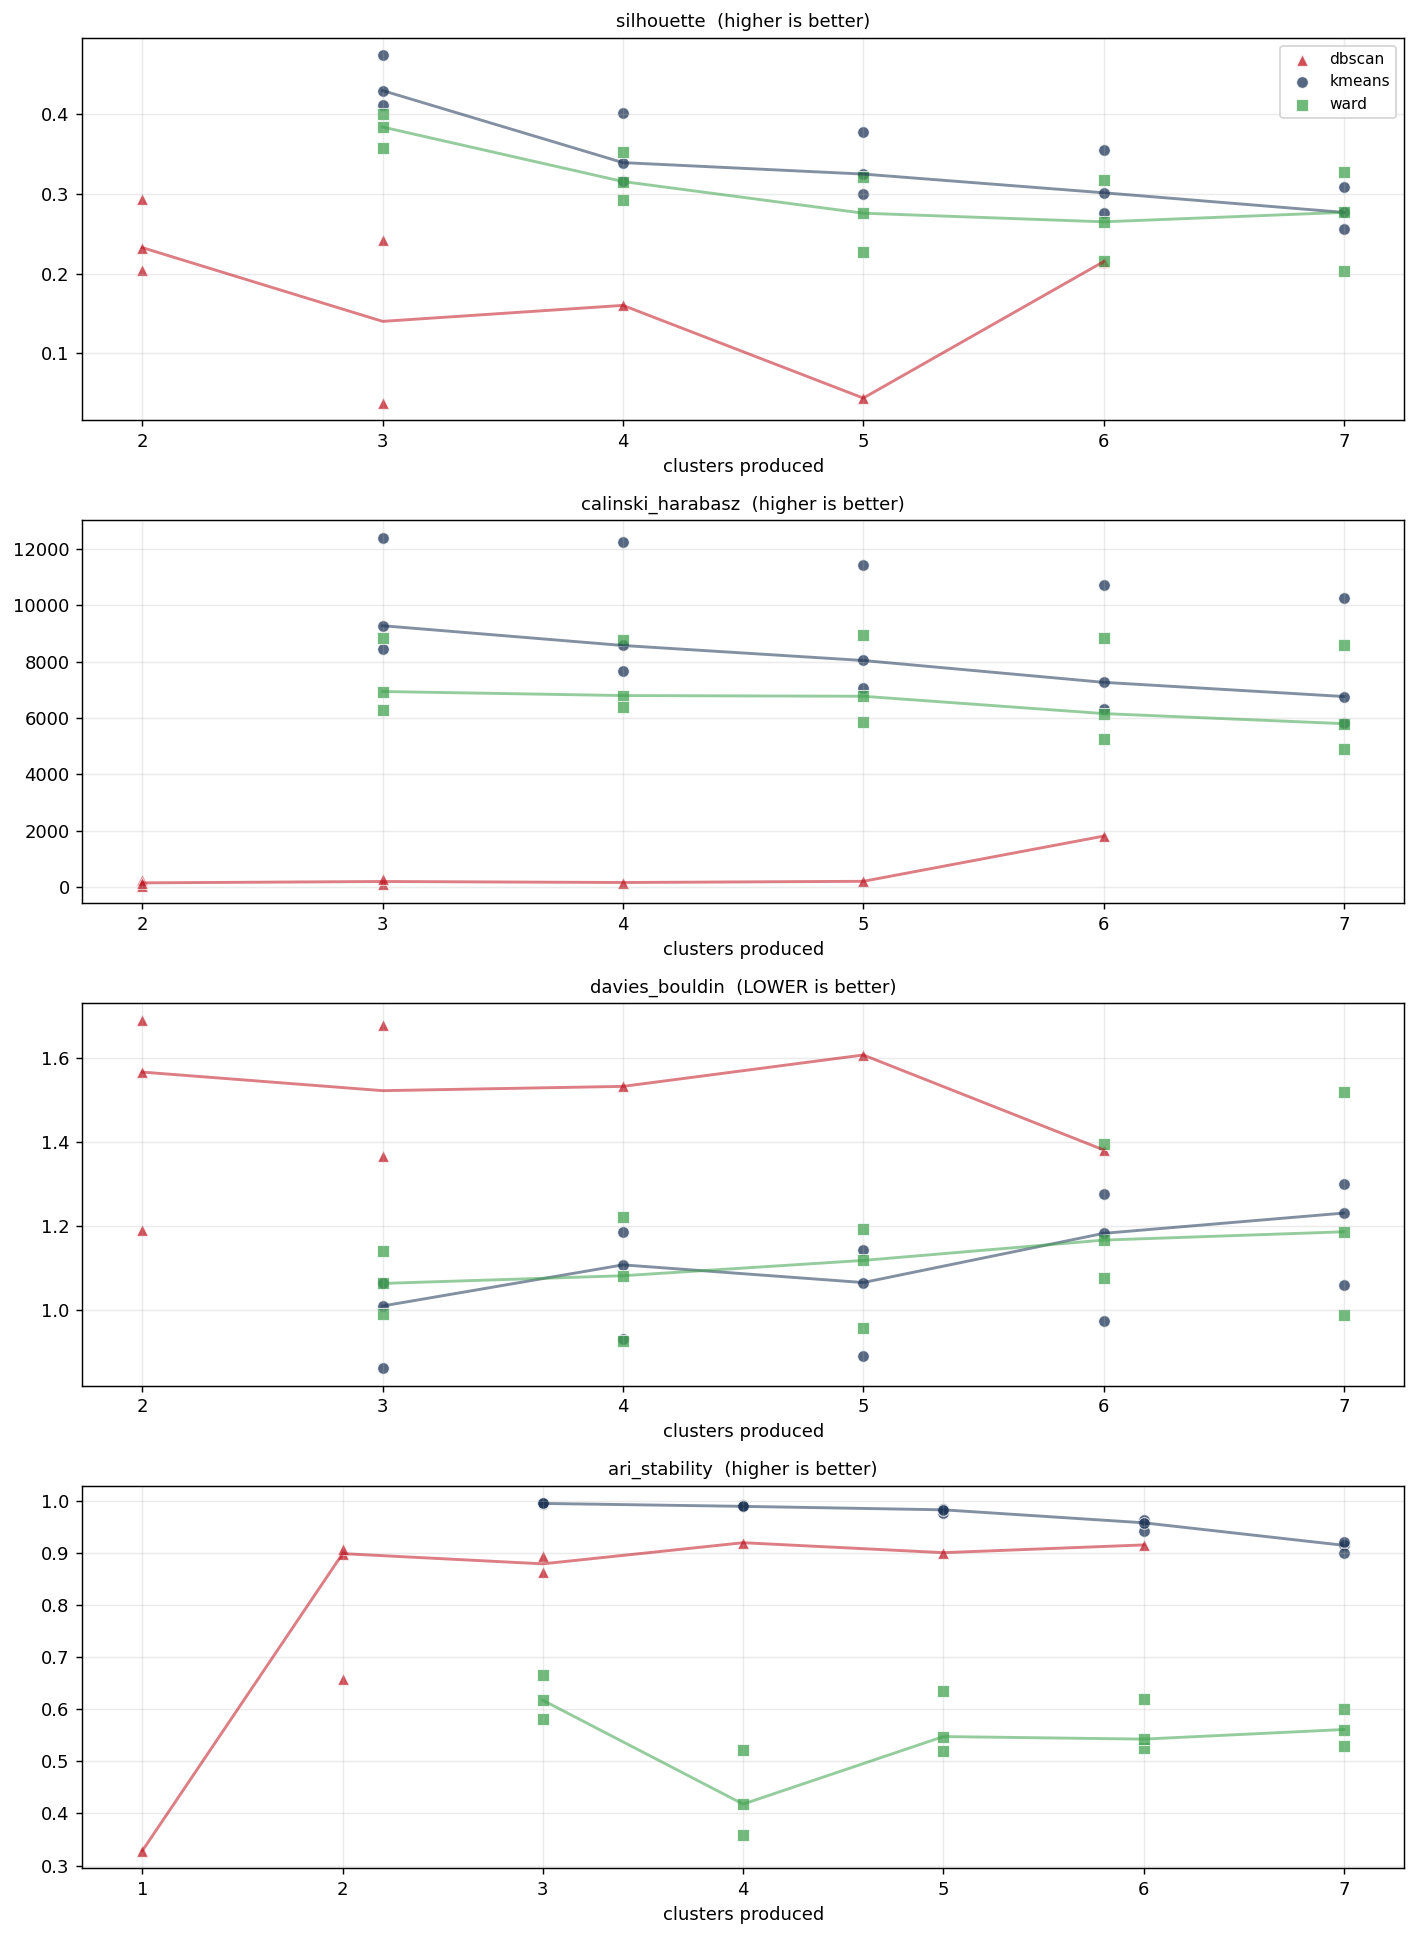

metric               picks          at
silhouette           3 clusters     kmeans, param=3.0, 3 PCs
calinski_harabasz    3 clusters     kmeans, param=3.0, 3 PCs
davies_bouldin       3 clusters     kmeans, param=3.0, 3 PCs
ari_stability        3 clusters     kmeans, param=3.0, 5 PCs

calinski_harabasz against cluster count (k-means, 5 PCs) -- note the trend:
   3:9,273  4:8,571  5:8,039  6:7,265  7:6,761
[results read-only] nb05: 1 key(s) verified against the ledger, nothing written


In [3]:
# WHAT: the four metrics, every grid cell, plotted against the number of clusters
#       the run ACTUALLY produced rather than against the parameter asked for.
# WHY:  k-means and Ward take k directly; DBSCAN takes eps and decides the cluster
#       count itself. Plotting all three against "k" would put eps=0.42 on the same
#       axis as k=4. Realised cluster count is the one x-axis they share.
METRICS = ["silhouette", "calinski_harabasz", "davies_bouldin", "ari_stability"]
BETTER = {"silhouette": "higher", "calinski_harabasz": "higher",
          "davies_bouldin": "LOWER", "ari_stability": "higher"}
STYLE = {"kmeans": ("#1d3557", "o"), "ward": ("#3fa34d", "s"),
         "dbscan": ("#c1121f", "^")}

fig, axes = plt.subplots(4, 1, figsize=(11.0, 15.0))
for ax, m in zip(axes, METRICS):
    for algo, sub_g in grid.groupby("algorithm"):
        colour, marker = STYLE[algo]
        s = sub_g.dropna(subset=[m]).sort_values("n_clusters")
        if not len(s):
            continue
        ax.scatter(s["n_clusters"], s[m], c=colour, marker=marker, s=42,
                   alpha=0.75, label=algo, edgecolor="white", linewidth=0.6)
        med = s.groupby("n_clusters")[m].median()
        ax.plot(med.index, med.values, color=colour, lw=1.6, alpha=0.55)
    ax.set_title(m + "  (" + BETTER[m] + " is better)", fontsize=10)
    ax.set_xlabel("clusters produced")
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8.5)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "05_cluster_metrics.png", bbox_inches="tight")
plt.show()

# The disagreement, quantified rather than described.
print("%-20s %-14s %s" % ("metric", "picks", "at"))
picks = {}
for m in METRICS:
    s = grid.dropna(subset=[m])
    best = s.loc[s[m].idxmin() if m == "davies_bouldin" else s[m].idxmax()]
    picks[m] = int(best["n_clusters"])
    print("%-20s %-14s %s, param=%s, %d PCs" % (
        m, str(int(best["n_clusters"])) + " clusters", best["algorithm"],
        best["param"], int(best["n_components"])))

sub5 = grid[(grid.algorithm == "kmeans") & (grid.n_components == 5)].sort_values("n_clusters")
print("")
print("calinski_harabasz against cluster count (k-means, 5 PCs) -- note the trend:")
print("   " + "  ".join(str(int(r.n_clusters)) + ":" + format(r.calinski_harabasz, ",.0f")
                        for r in sub5.itertuples()))

R.save("nb05", {"metric_picks_n_clusters": picks});


**What this shows:** Every grid cell scored on the four metrics, k-means, Ward and DBSCAN together.

**What I see:** All four metrics pick k = 3: silhouette, Davies–Bouldin and Calinski–Harabasz at k-means on 3 PCs, ARI stability at k-means on 5 PCs. The chosen configuration (k-means, k = 3, 5 PCs) scores ARI 0.996, silhouette 0.429, DB 1.010, CH 9,273. Best ARI by algorithm: k-means 0.996, DBSCAN 0.920, Ward 0.666. DBSCAN's best has silhouette 0.160 and 4 clusters with 6.9% of days as noise. Calinski–Harabasz falls as k rises: 9,273 → 8,571 → 8,039 → 7,265 → 6,761 for k = 3…7 at 5 PCs.

**What it means:** The metrics agree on k; they disagree on the number of components. ARI picks 5 PCs (0.9958) over 3 PCs (0.9940), while 3 PCs scores better on the other three (silhouette 0.473 vs 0.429). Those three are computed in different PCA spaces, so they cannot rank component counts; ARI, which compares partitions of the same days, can.

**What I do:** Keep k-means with k = 3. The 5-PC choice rests on a 0.002 ARI margin, so I state it as a limitation. Silhouette 0.429 is modest: the regimes are regions of a continuum, and DBSCAN finding no dense islands agrees with that.


### 5.4 — Name the regimes

Plot the cluster centroids as 24-hour local-time profiles and give each a physical name. "Cluster 2" means nothing to a grid operator.


chosen: kmeans with param=3.0 on 5 PCs (ari=0.996, sil=0.429)

cluster         n    argmin     belly  eve ramp
0            2496        23     0.635     0.173
1            7782         4     0.693     0.364
2            2791        13     0.111     0.841
cluster 0: minimum 0.189 at hour 23, maximum 0.900 at hour 9
cluster 1: minimum 0.026 at hour 4, maximum 0.928 at hour 18
cluster 2: minimum 0.076 at hour 13, maximum 0.917 at hour 20

regime names, derived from the shapes: 0 -> winter-shaped, 1 -> conventional, 2 -> DUCK


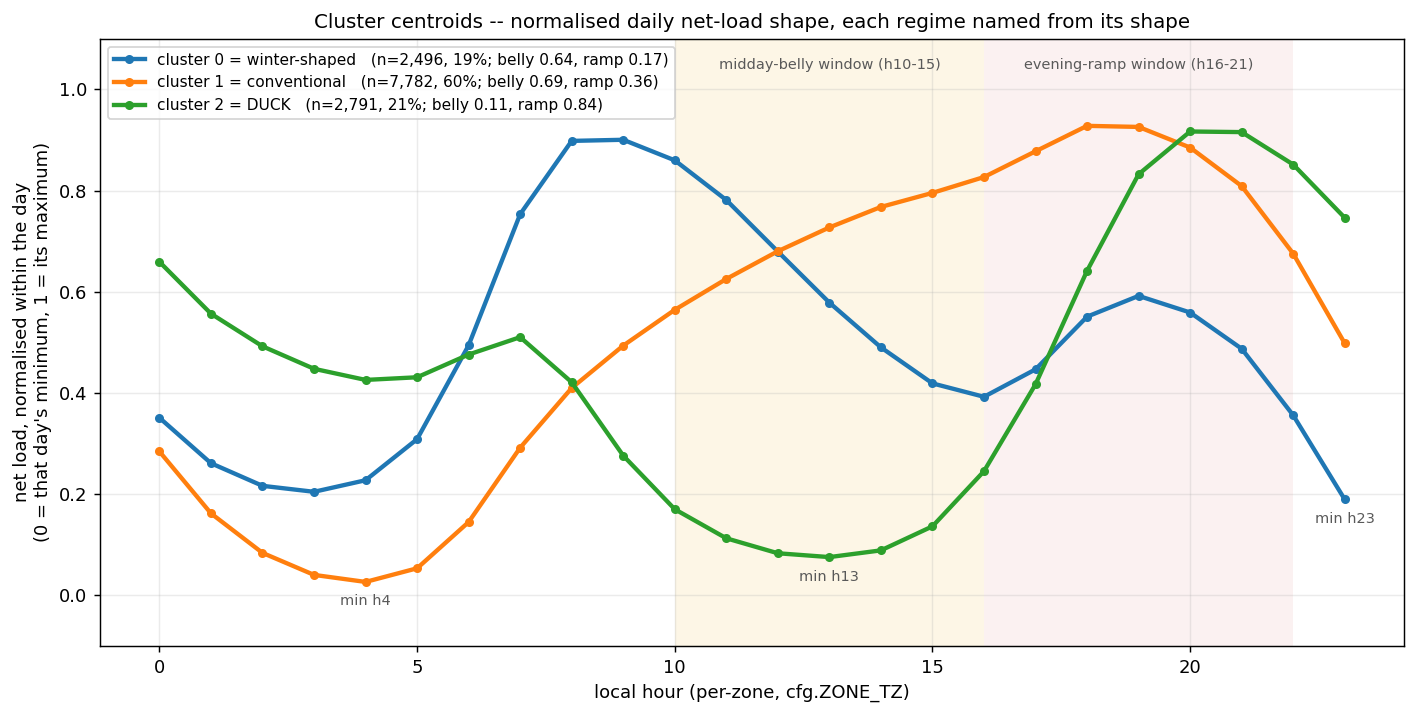

PCA: 5 components keep 94.8% of the shape variance
[results read-only] nb05: 10 key(s) verified against the ledger, nothing written


In [4]:
# The winner is chosen on ARI STABILITY, not silhouette. Silhouette rewards tight
# round blobs and rises when a partition is merely tidy; ARI stability asks whether
# the SAME partition reappears when the data is resampled. A regime that vanishes
# under an 80% resample is an artefact of this sample, not an operating state.
best_cfg = grid.sort_values("ari_stability", ascending=False).iloc[0]
print(f"chosen: {best_cfg['algorithm']} with param={best_cfg['param']} "
      f"on {int(best_cfg['n_components'])} PCs "
      f"(ari={best_cfg['ari_stability']:.3f}, sil={best_cfg['silhouette']:.3f})")

_kw = dict(n_components=int(best_cfg["n_components"]),
           algorithm=str(best_cfg["algorithm"]))
if best_cfg["algorithm"] == "dbscan":
    _kw.update(eps=float(best_cfg["param"]), min_samples=int(MIN_SAMPLES))
else:
    _kw.update(k=int(best_cfg["param"]))
pipe = P.make_clustering_pipeline(**_kw).fit(shapes)
labels = pd.Series(pipe.named_steps["clust"].labels_, index=shapes.index, name="cluster")

centroids = shapes.groupby(labels).mean()

# The physical reading: where is the minimum, how deep is the belly, how steep the ramp.
print("\n%-9s %7s %9s %9s %9s" % ("cluster", "n", "argmin", "belly", "eve ramp"))
summary = []
for c, row in centroids.iterrows():
    belly = float(row.iloc[10:16].mean())
    ramp = float(row.iloc[16:22].max() - row.iloc[10:16].min())
    summary.append({"cluster": int(c), "n": int((labels == c).sum()),
                    "argmin_hour": int(row.values.argmin()),
                    "midday_belly": round(belly, 3), "evening_ramp": round(ramp, 3)})
    print("%-9d %7d %9d %9.3f %9.3f" % (c, summary[-1]["n"],
                                        summary[-1]["argmin_hour"], belly, ramp))
for c, row in centroids.iterrows():
    print(f"cluster {int(c)}: minimum {row.min():.3f} at hour {int(row.values.argmin())}, "
          f"maximum {row.max():.3f} at hour {int(row.values.argmax())}")

# Regime NAMES are derived from the shapes, not hard-coded. Cluster numbering is
# arbitrary -- KMeans renumbers when the data changes -- so a fixed {id: name} map
# silently renames the regimes the day the partition renumbers. Notebooks 6 and 8
# read this key instead of carrying their own copy of the map. The rule: the duck
# is the deepest midday belly; "conventional" is the plurality of what remains;
# the residual morning-peak shape is named winter-shaped, and 5.4b checks that
# name against weather the clustering never saw (it must be the coldest regime).
_duck = min(summary, key=lambda r: r["midday_belly"])["cluster"]
_rest = [r for r in summary if r["cluster"] != _duck]
_conv = max(_rest, key=lambda r: r["n"])["cluster"] if _rest else None
regime_names = {}
for _r in summary:
    _c = _r["cluster"]
    if _c == _duck:
        regime_names[str(_c)] = "DUCK"
    elif _c == _conv:
        regime_names[str(_c)] = "conventional"
    elif len(_rest) == 2:
        regime_names[str(_c)] = "winter-shaped"
    else:
        regime_names[str(_c)] = f"cluster {_c}"
print("\nregime names, derived from the shapes: "
      + ", ".join(f"{c} -> {n}" for c, n in sorted(regime_names.items())))

# THE FIGURE IS DRAWN AFTER THE NAMES EXIST, so the legend can carry them. A legend
# that reads "cluster 2" makes the reader do the lookup this cell has already done,
# and the two windows the summary statistics are computed over are shaded so
# "belly" and "ramp" are visible quantities rather than words.
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.axvspan(10, 16, color="#f2c14e", alpha=0.14, lw=0)
ax.axvspan(16, 22, color="#c1121f", alpha=0.06, lw=0)
for c, row in centroids.iterrows():
    _n = int((labels == c).sum())
    _r = next(r for r in summary if r["cluster"] == int(c))
    ax.plot(row.index, row.values, lw=2.4, marker="o", ms=4,
            label=(f"cluster {c} = {regime_names[str(c)]}   (n={_n:,}, {_n / len(labels):.0%}; "
                   f"belly {_r['midday_belly']:.2f}, ramp {_r['evening_ramp']:.2f})"))
    ax.annotate(f"min h{_r['argmin_hour']}", (_r["argmin_hour"], float(row.values.min())),
                xytext=(0, -13), textcoords="offset points", ha="center", fontsize=8, color="0.35")
ax.annotate("midday-belly window (h10-15)", (13, 1.04), ha="center", fontsize=8, color="0.35")
ax.annotate("evening-ramp window (h16-21)", (19, 1.04), ha="center", fontsize=8, color="0.35")
ax.set_ylim(-0.1, 1.1)
ax.set_xlabel("local hour (per-zone, cfg.ZONE_TZ)")
ax.set_ylabel("net load, normalised within the day\n(0 = that day's minimum, 1 = its maximum)")
ax.set_title("Cluster centroids -- normalised daily net-load shape, each regime named from its shape",
             fontsize=11)
ax.legend(fontsize=8.5, loc="upper left"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "05_centroids.png", bbox_inches="tight")
plt.show()

# How much of the daily-shape variance the chosen PCs keep -- the number that
# answers "why PCA before k-means, and what does the projection throw away".
_evr = pipe.named_steps["pca"].explained_variance_ratio_
print(f"PCA: {len(_evr)} components keep {float(_evr.sum()):.1%} "
      f"of the shape variance")

R.save("nb05", {
    "chosen_algorithm": str(best_cfg["algorithm"]),
    "chosen_param": float(best_cfg["param"]),
    "chosen_pcs": int(best_cfg["n_components"]),
    "ari_stability": float(best_cfg["ari_stability"]),
    "silhouette": float(best_cfg["silhouette"]),
    "n_clusters": int(labels.nunique()),
    "centroid_summary": summary,
    "regime_names": regime_names,
    "pca_explained_variance_ratio": [float(v) for v in _evr],
    "pca_explained_variance_total": float(_evr.sum()),
});


**Figure: `05_centroids.png`.**

**What this shows:** Each cluster's mean normalised shape by local hour. Normalising removes level, so only shape is compared. The 5 principal components keep 94.8% of the shape variance.

**What I see:** Three different shapes:

- **Cluster 2 (n = 2,791, 21.4%), duck:** minimum at hour 13, midday belly 0.111, evening ramp 0.841, the steepest.
- **Cluster 1 (n = 7,782, 59.5%), conventional:** minimum at hour 4, rising to a peak at hour 18, belly 0.693, ramp 0.364.
- **Cluster 0 (n = 2,496, 19.1%), winter-shaped:** peak at hour 9, declining through the afternoon, minimum at hour 23, ramp 0.173, the smallest.

The names are derived in code (`0 → winter-shaped, 1 → conventional, 2 → DUCK`): the duck is the deepest belly, conventional is the largest of the rest, and the remaining morning-peak regime is winter-shaped. Cluster numbers are arbitrary, so later notebooks read the names from `nb05.regime_names`.

**What it means:** The duck regime's hour-13 minimum is solar noon, and its 0.841 ramp is the operational problem the forecast serves. Clusters 0 and 1 have similar bellies (0.635 and 0.693); only the ramp, the minimum hour and the profile separate them. Local-hour indexing matters: on UTC hours the zones' solar noons would not line up.

**What I do:** Use the regime names from `regime_names`, and use a past day's label as the admissible forecast feature (§5.5).


### 5.4b — Weather on each regime's days

Join the daily labels back to the panel and compute mean weather per regime and its departure from the whole-panel mean. The clustering never sees weather, so if the regimes are physical they should still separate on it. Read the departures, not the levels. The prediction tested: duck days should be sunnier than average. Caveat: the panel spans six grids, so a regime drawn mostly from one zone can look different for geographic reasons; §5.4c checks that.


regime weather signature over 13,069 labelled zone-days (100.0% with complete weather)

--- mean weather per regime ---


,temp,humidity,wind_speed,cloud_cover,ghi,dni_horiz,dhi,wind_speed_100m,wind_gust,apparent_temp,dew_point,snowfall,snow_depth,precipitation,pressure
cluster,,,,,,,,,,,,,,,
0,6.18,72.03,12.13,59.64,133.03,84.63,48.40,21.09,23.48,2.79,0.90,0.01,0.03,0.12,999.29
1,16.45,68.15,13.36,52.23,192.46,131.39,61.07,21.87,25.73,15.28,9.77,0.00,0.01,0.15,996.58
2,16.46,63.59,9.70,38.36,211.65,158.31,53.34,14.03,19.66,15.12,8.14,0.00,0.00,0.06,1003.54


--- departure from the whole-panel daily mean ---


,temp,humidity,wind_speed,cloud_cover,ghi,dni_horiz,dhi,wind_speed_100m,wind_gust,apparent_temp,dew_point,snowfall,snow_depth,precipitation,pressure
cluster,,,,,,,,,,,,,,,
0,-8.27,4.10,-0.22,8.92,-51.84,-43.29,-8.54,1.03,-0.53,-10.01,-6.79,0.0,0.02,-0.00,0.72
1,2.00,0.23,1.01,1.51,7.60,3.47,4.13,1.80,1.71,2.47,2.08,0.0,-0.00,0.02,-1.98
2,2.01,-4.33,-2.65,-12.37,26.78,30.39,-3.60,-6.04,-4.36,2.32,0.45,-0.0,-0.01,-0.06,4.98


--- which columns separate the regimes? (cluster spread / daily sd) ---
temp               1.043
apparent_temp      1.039
dew_point          0.948
ghi                0.876
wind_speed_100m    0.874
dni_horiz          0.872
wind_gust          0.664
cloud_cover        0.662
wind_speed         0.661
humidity           0.567
snow_depth         0.538
dhi                0.492
pressure           0.433
precipitation      0.250
snowfall           0.188

the four most discriminating weather columns: ['temp', 'apparent_temp', 'dew_point', 'ghi']
   regime 0: temp 6.2 (-8.3), apparent_temp 2.8 (-10.0), dew_point 0.9 (-6.8), ghi 133.0 (-51.8)
   regime 1: temp 16.5 (+2.0), apparent_temp 15.3 (+2.5), dew_point 9.8 (+2.1), ghi 192.5 (+7.6)
   regime 2: temp 16.5 (+2.0), apparent_temp 15.1 (+2.3), dew_point 8.1 (+0.5), ghi 211.7 (+26.8)

EXTERNAL VALIDATION — the duck regime (cluster 2) against the panel mean:
   winter-shaped is cluster 0; coldest regime is cluster 0 (6.2 C) -> name holds
   cloud cov

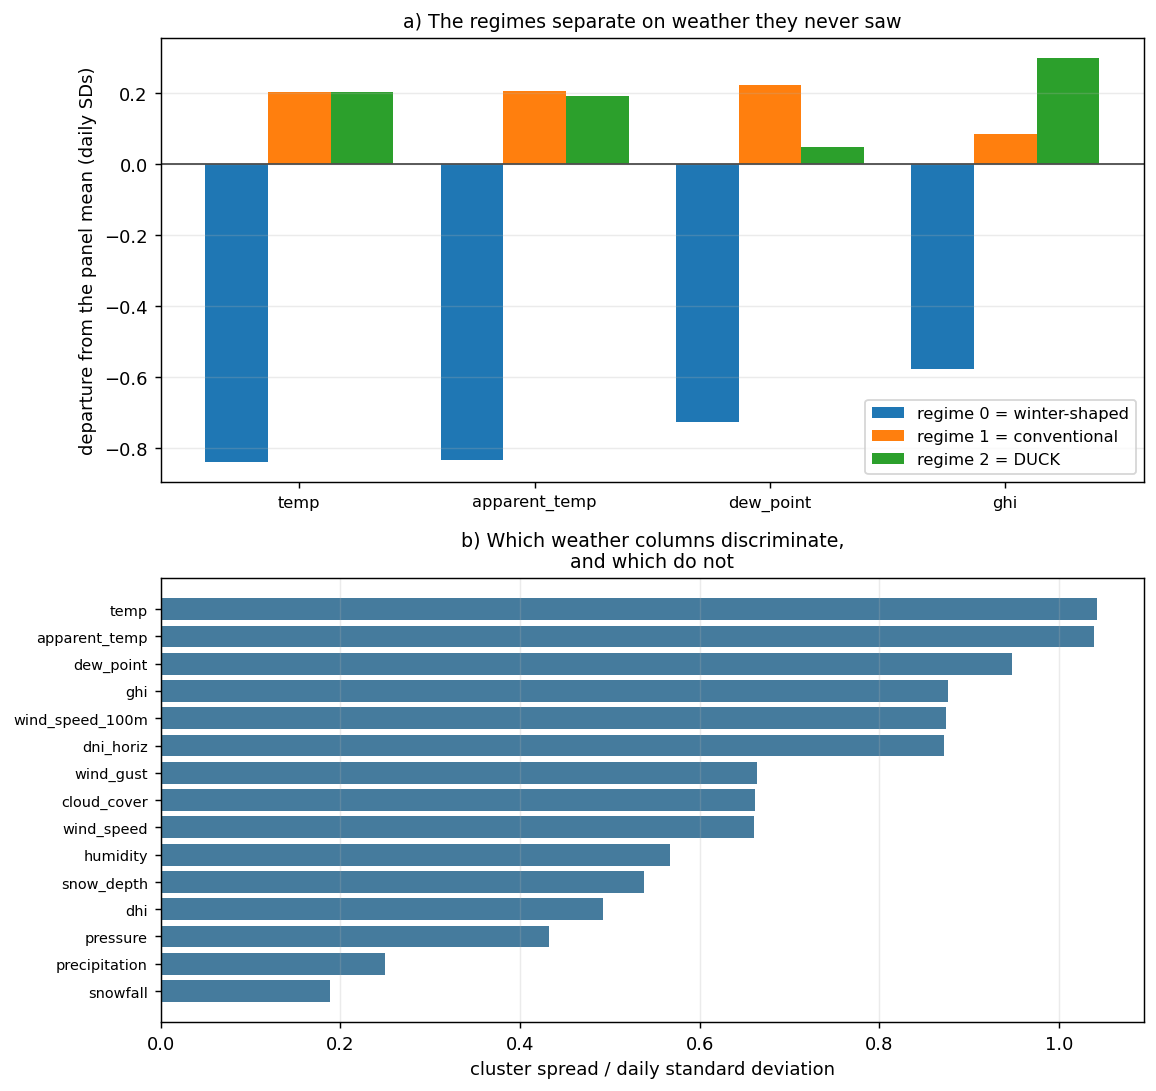

[results read-only] nb05: 1 key(s) verified against the ledger, nothing written


In [5]:
# WHAT: mean weather per regime, and each regime's departure from the panel mean.
# WHY:  the regimes are built from the SHAPE of the daily net-load curve and see no
#       weather at all. If they are physical rather than arithmetic, weather should
#       separate across them anyway. That is an external validation.
# NOTE: this also puts a source under the report's "Weather signature" column, which
#       until 2026-08-23 was three numbers no cell produced.

WEATHER_COLS = [c for c in cfg.WEATHER_FEATURES if c in df.columns]

# THE JOIN MUST USE THE SAME CLOCK THE SHAPES USE. `daily_shape_matrix` indexes by
# LOCAL date per zone, because a daily shape is a fact about the sun. Averaging
# weather over a UTC date and joining it to a local-date label would offset a sixth
# to a third of every zone's day (4 to 8 hours) onto the wrong regime -- silently, because the join
# would still succeed and the row count would still be right.
_local = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
for _z, _tz in cfg.ZONE_TZ.items():
    _m = (df[cfg.GROUP_COL] == _z).to_numpy()
    if _m.any():
        _local[_m] = (df.loc[_m, cfg.TIME_COL].dt.tz_localize("UTC")
                      .dt.tz_convert(_tz).dt.tz_localize(None))
_w = df[[cfg.GROUP_COL] + WEATHER_COLS].copy()
_w["date"] = _local.dt.date
daily_w = _w.groupby([cfg.GROUP_COL, "date"])[WEATHER_COLS].mean()

sig = daily_w.reindex(labels.index)
sig_mean = sig.groupby(labels.to_numpy()).mean()
sig_mean.index.name = "cluster"
panel_mean = daily_w.mean()
delta = sig_mean - panel_mean

print(f"regime weather signature over {len(sig):,} labelled zone-days "
      f"({sig.notna().all(axis=1).mean():.1%} with complete weather)")
print("\n--- mean weather per regime ---")
display(sig_mean.round(2))
print("--- departure from the whole-panel daily mean ---")
display(delta.round(2))

# The headline signature: the columns that separate the regimes most, measured as the
# spread across clusters relative to the column's own daily spread. Ranking them means
# the report quotes the columns that actually discriminate rather than the ones someone
# happened to look at.
spread = ((sig_mean.max() - sig_mean.min()) / daily_w.std()).sort_values(
    ascending=False)
print("--- which columns separate the regimes? (cluster spread / daily sd) ---")
print(spread.round(3).to_string())

TOP = list(spread.head(4).index)
print(f"\nthe four most discriminating weather columns: {TOP}")
for c in sorted(sig_mean.index):
    bits = ", ".join(f"{col} {sig_mean.loc[c, col]:.1f} ({delta.loc[c, col]:+.1f})"
                     for col in TOP)
    print(f"   regime {c}: {bits}")

# --- the prediction, tested ------------------------------------------------
# The duck regime (deep midday belly, steep evening ramp -- see 5.4). If the
# shape clustering is finding physics rather than arithmetic, its days must be
# SUNNIER than average: less cloud and more irradiance. Nothing in the clustering
# was told about either column.
# The duck is the regime with the DEEPEST midday belly, read from the shape
# summary built in 5.4 rather than assumed to be cluster 1. Cluster numbering
# is arbitrary and moves with the seed; hardcoding "1" would silently name the
# wrong regime the day the partition renumbers.
DUCK = int(min(summary, key=lambda r: r["midday_belly"])["cluster"])
duck_cloud = float(delta.loc[DUCK, "cloud_cover"]) if "cloud_cover" in delta else float("nan")
duck_ghi = float(delta.loc[DUCK, "ghi"]) if "ghi" in delta else float("nan")
print(f"\nEXTERNAL VALIDATION — the duck regime (cluster {DUCK}) against the panel mean:")

# The winter-shaped NAME is validated here too: it must be the coldest regime,
# or the name is asserting weather the shapes did not earn.
_winter = [c for c, n in regime_names.items() if n == "winter-shaped"]
if _winter and "temp" in sig_mean.columns:
    _coldest = str(int(sig_mean["temp"].idxmin()))
    _w_ok = _winter[0] == _coldest
    print(f"   winter-shaped is cluster {_winter[0]}; coldest regime is "
          f"cluster {_coldest} ({sig_mean['temp'].min():.1f} C) -> "
          + ("name holds" if _w_ok else "NAME DOES NOT HOLD -- report this"))
print(f"   cloud cover {duck_cloud:+.1f} pp        irradiance {duck_ghi:+.1f} W/m2")
holds = (duck_cloud < 0) and (duck_ghi > 0)
print("   -> " + ("HOLDS. The regimes were built from curve SHAPE alone and none of "
                  "them\n      saw a weather column; the duck days come out sunnier "
                  "anyway, which is\n      evidence the segmentation is physical."
                  if holds else
                  "FAILS. The duck regime is not sunnier than average, which means the "
                  "shape\n      clustering is not tracking the mechanism it is named "
                  "for. Reported as a\n      finding rather than smoothed over."))

fig, axes = plt.subplots(2, 1, figsize=(9.0, 8.5))
ax = axes[0]
xs = np.arange(len(TOP))
W = 0.8 / len(sig_mean)
for j, c in enumerate(sorted(sig_mean.index)):
    ax.bar(xs + j * W - 0.4 + W / 2, [delta.loc[c, col] / daily_w[col].std()
                                      for col in TOP], W, label=f"regime {c} = {regime_names[str(c)]}")
ax.axhline(0, color="0.3", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(TOP, fontsize=9)
ax.set_ylabel("departure from the panel mean (daily SDs)")
ax.set_title("a) The regimes separate on weather they never saw", fontsize=10.5)
ax.legend(fontsize=9); ax.grid(alpha=0.25, axis="y")

ax = axes[1]
ax.barh(range(len(spread))[::-1], spread.values, color="#457b9d")
ax.set_yticks(range(len(spread))[::-1]); ax.set_yticklabels(spread.index, fontsize=8)
ax.set_xlabel("cluster spread / daily standard deviation")
ax.set_title("b) Which weather columns discriminate,\nand which do not", fontsize=10.5)
ax.grid(alpha=0.25, axis="x")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "05_regime_weather.png", bbox_inches="tight")
plt.show()

R.save("nb05", {"regime_weather_signature": {
    "columns": WEATHER_COLS,
    "mean_by_regime": {str(c): {k: float(v) for k, v in sig_mean.loc[c].items()}
                       for c in sig_mean.index},
    "delta_from_panel_mean": {str(c): {k: float(v) for k, v in delta.loc[c].items()}
                              for c in delta.index},
    "panel_daily_mean": {k: float(v) for k, v in panel_mean.items()},
    "discrimination_ranking": {k: float(v) for k, v in spread.items()},
    "labelled_zone_days": int(len(sig)),
    "duck_cluster": DUCK,
    "duck_cloud_delta_pp": duck_cloud,
    "duck_ghi_delta_wm2": duck_ghi,
    "duck_is_sunnier_than_average": bool(holds),
}});


**What this shows:** Mean weather per regime and its departure from the panel mean, over 13,069 labelled zone-days and 15 weather columns.

**What I see:** The columns that separate the regimes most are `temp` (1.04), `apparent_temp` (1.04), `dew_point` (0.948), `ghi` (0.876) and `wind_speed_100m` (0.874). The weakest are `pressure`, `precipitation` and `snowfall`. Pooled, the duck days are sunnier than average.

**What it means:** Weather the clustering never saw separates the regimes, which suggests the partition picks up something physical. Weather is averaged on the same local-date clock as the shapes; a UTC join would put 4 to 8 hours of each day on the wrong regime without any error.

**What I do:** Report the full ranking and test geography in §5.4c. Result there: the temperature signature survives within zone, the irradiance signature does not.

### 5.4c — Are the regimes zones in disguise?

Cross-tabulate zone against regime, then repeat the §5.4b weather check within each zone, as a departure from that zone's own mean. Within one zone geography is fixed, so a contrast that survives belongs to the daily shape. Read the crosstab down the columns (where each regime's days come from). Regimes with fewer than `MIN_ZONE_DAYS` days in a zone are excluded.

--- zone x regime, 13,069 labelled zone-days ---


regime,DUCK,conventional,winter-shaped
zone,,,
BPAT,60,1077,1039
CISO,2148,32,2
ERCO,358,1479,348
MISO,62,1609,512
NYIS,85,2033,63
SWPP,78,1552,532


--- share of each REGIME's days contributed by each zone (read down) ---


regime,DUCK,conventional,winter-shaped
zone,,,
BPAT,2.1,13.8,41.6
CISO,77.0,0.4,0.1
ERCO,12.8,19.0,13.9
MISO,2.2,20.7,20.5
NYIS,3.0,26.1,2.5
SWPP,2.8,19.9,21.3


most concentrated regime: 'DUCK' -- 77% of its days are CISO, and 98% of CISO's days are DUCK
   -> CONFOUNDED WITH GEOGRAPHY. The pooled weather contrast for this regime is largely a statement about CISO.

--- weather by regime WITHIN zone (deviation from that zone's own mean) ---


zone_days  temp_vs_zone_mean  cloud_cover_vs_zone_mean  ghi_vs_zone_mean   thin
zone regime                                                                                        
BPAT DUCK                  60              -2.03                      9.62            -26.67  False
     conventional        1077               3.72                     -8.89             37.23  False
     winter-shaped       1039              -3.74                      8.66            -37.05  False
CISO DUCK                2148              -0.01                     -0.33              1.23  False
     conventional          32               0.33                     24.80            -83.75  False
     winter-shaped          2               1.10                    -37.53             17.13   True
ERCO DUCK                 358              -4.49                    -10.93             -9.96  False
     conventional        1479               3.35                      2.13             13.58  False
     winter-shaped        348              -9.61                      2.17            -47.47  False
MISO DUCK                  62              -5.25                     -0.78            -18.30  False
     conventional        1609               3.74                     -1.68             16.50  False
     winter-shaped        512             -11.11                      5.38            -49.64  False
NYIS DUCK                  85              -2.65                    -19.47             51.40  False
     conventional        2033               0.32                      1.31             -2.96  False
     winter-shaped         63              -6.64                    -16.07             26.04  False
SWPP DUCK                  78              -7.45                      0.49            -29.79  False
     conventional        1552               3.15                     -0.42             16.27  False
     winter-shaped        532              -8.11                      1.16            -43.08  False


   'winter-shaped' colder than its zone: holds in 5 of 5 zones with >= 30 such days; margin in the claimed direction, + = holds [BPAT +3.7, ERCO +9.6, MISO +11.1, NYIS +6.6, SWPP +8.1]
      -> SURVIVES the within-zone check -- this is a property of the daily shape.

   'DUCK' brighter than its zone: holds in 2 of 6 zones with >= 30 such days; margin in the claimed direction, + = holds [BPAT -26.7, CISO +1.2, ERCO -10.0, MISO -18.3, NYIS +51.4, SWPP -29.8]
      -> DOES NOT SURVIVE. The pooled version of this contrast was carried by between-zone differences, and 5.4b's reading of it has to be narrowed.

   'DUCK' less cloudy than its zone: holds in 4 of 6 zones with >= 30 such days; margin in the claimed direction, + = holds [BPAT -9.6, CISO +0.3, ERCO +10.9, MISO +0.8, NYIS +19.5, SWPP -0.5]
      -> DOES NOT SURVIVE. The pooled version of this contrast was carried by between-zone differences, and 5.4b's reading of it has to be narrowed.


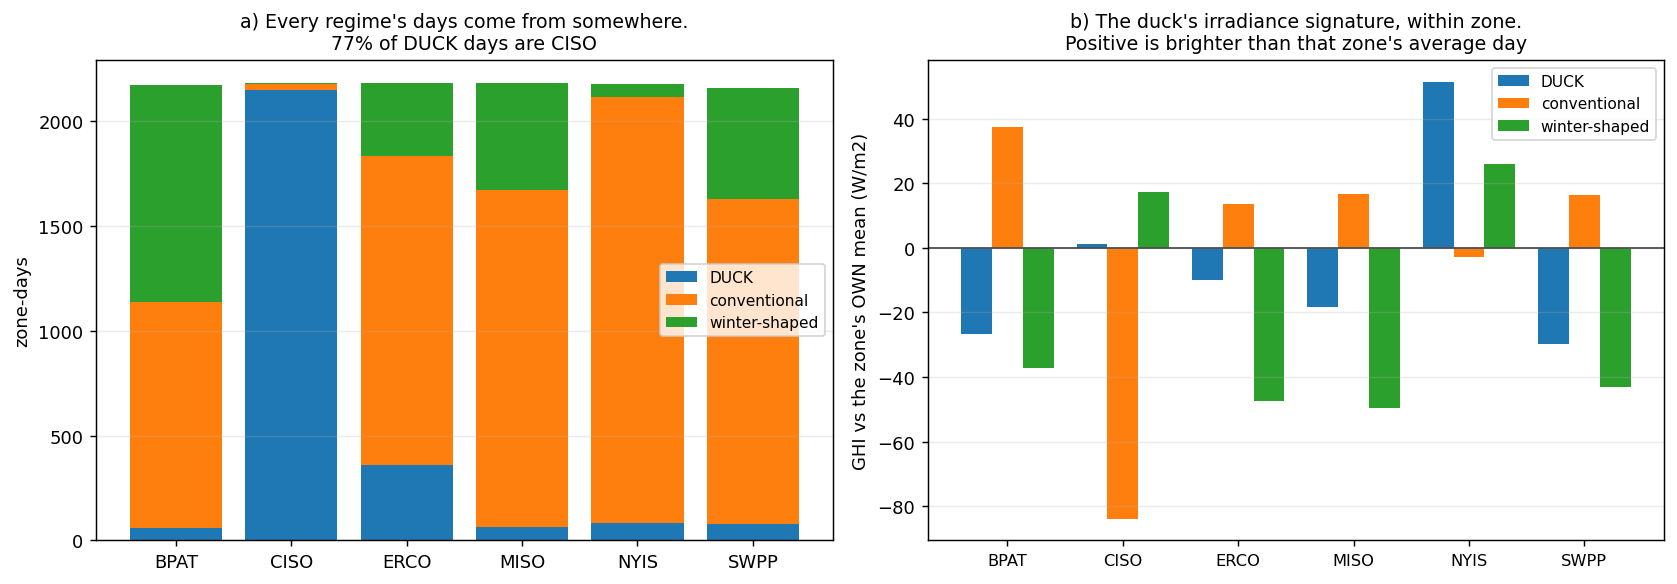

[results read-only] nb05: 5 key(s) verified against the ledger, nothing written


In [6]:
# WHAT: zone x regime, and 5.4b's weather check re-measured within each zone.
# WHY:  5.4b validated the regimes against weather they never saw, POOLED across six
#       grids. If a regime is mostly one zone, that validation is confounded with
#       geography, and the honest thing is to measure it where geography cannot help.
# NOTE: the computation lives in `src.reserve`, which `scripts/conditional_reserve.py`
#       and notebook 08 also call, so this notebook and the report tables cannot
#       disagree about what the numbers are.

from src import reserve as RS

MIN_ZONE_DAYS = 30        # below this, a zone-regime cell is an anecdote

lab_frame = labels.reset_index()                      # zone, date, cluster
crosstab = RS.regime_by_zone(lab_frame, regime_names)
within = RS.regime_weather_within_zone(df, lab_frame, regime_names)

print(f"--- zone x regime, {int(crosstab.to_numpy().sum()):,} labelled zone-days ---")
display(crosstab)

# DOWN the columns: where do each regime's days come from? That is the question.
col_share = crosstab.div(crosstab.sum(axis=0), axis=1)
row_share = crosstab.div(crosstab.sum(axis=1), axis=0)
print("--- share of each REGIME's days contributed by each zone (read down) ---")
display((col_share * 100).round(1))

worst_regime = col_share.max().idxmax()
worst_zone = col_share[worst_regime].idxmax()
conc = float(col_share.loc[worst_zone, worst_regime])
print(f"most concentrated regime: {worst_regime!r} -- {conc:.0%} of its days are "
      f"{worst_zone}, and {row_share.loc[worst_zone, worst_regime]:.0%} of {worst_zone}'s "
      f"days are {worst_regime}")
print("   -> " + ("CONFOUNDED WITH GEOGRAPHY. The pooled weather contrast for this "
                  f"regime is largely a statement about {worst_zone}."
                  if conc > 0.5 else
                  "no single zone dominates any regime; the pooled contrast in 5.4b "
                  "stands as it is."))

# --- 5.4b's two predictions, re-tested WITHIN zone -------------------------
# The cold prediction and the sunny prediction are separable here, and they do not
# survive equally. Cells thinner than MIN_ZONE_DAYS are excluded from the verdict and
# printed anyway, because "CISO has two winter-shaped days in six years" is itself a
# fact about the grid.
w = within.copy()
w["thin"] = w["zone_days"] < MIN_ZONE_DAYS
print("\n--- weather by regime WITHIN zone (deviation from that zone's own mean) ---")
display(w.set_index(["zone", "regime"]).round(2))

WINTER = [n for n in regime_names.values() if n == "winter-shaped"]
DUCK_NAME = regime_names[str(DUCK)]
verdicts = {}
for name, col, sign, claim in [
        (WINTER[0] if WINTER else None, "temp_vs_zone_mean", -1, "colder than its zone"),
        (DUCK_NAME, "ghi_vs_zone_mean", +1, "brighter than its zone"),
        (DUCK_NAME, "cloud_cover_vs_zone_mean", -1, "less cloudy than its zone")]:
    if name is None or col not in w.columns:
        continue
    cells = w[(w["regime"] == name) & ~w["thin"]]
    ok = int((sign * cells[col] > 0).sum())
    verdicts[f"{name}/{col}"] = {"holds_in": ok, "of_zones": int(len(cells)),
                                 "survives": bool(ok == len(cells))}
    print(f"\n   {name!r} {claim}: holds in {ok} of {len(cells)} zones with "
          f">= {MIN_ZONE_DAYS} such days; margin in the claimed direction, + = holds "
          f"[{', '.join(f'{r.zone} {sign * getattr(r, col):+.1f}' for r in cells.itertuples())}]")
    print("      -> " + ("SURVIVES the within-zone check -- this is a property of the "
                         "daily shape." if ok == len(cells) else
                         "DOES NOT SURVIVE. The pooled version of this contrast was "
                         "carried by between-zone differences, and 5.4b's reading of it "
                         "has to be narrowed."))

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6))
ax = axes[0]
bottom = np.zeros(len(crosstab))
for rg in crosstab.columns:
    ax.bar(crosstab.index, crosstab[rg], bottom=bottom, label=rg)
    bottom += crosstab[rg].to_numpy()
ax.set_ylabel("zone-days"); ax.legend(fontsize=8.5)
ax.set_title(f"a) Every regime's days come from somewhere.\n{conc:.0%} of "
             f"{worst_regime} days are {worst_zone}", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[1]
piv = within.pivot(index="zone", columns="regime", values="ghi_vs_zone_mean")
xs = np.arange(len(piv))
W = 0.8 / len(piv.columns)
for j, rg in enumerate(piv.columns):
    ax.bar(xs + j * W - 0.4 + W / 2, piv[rg].to_numpy(), W, label=rg)
ax.axhline(0, color="0.3", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(piv.index, fontsize=9)
ax.set_ylabel("GHI vs the zone's OWN mean (W/m2)")
ax.set_title("b) The duck's irradiance signature, within zone.\n"
             "Positive is brighter than that zone's average day", fontsize=10.5)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "05_regime_vs_zone.png", bbox_inches="tight")
plt.show()

R.save("nb05", {
    "regime_by_zone": {z: {rg: int(crosstab.loc[z, rg]) for rg in crosstab.columns}
                       for z in crosstab.index},
    "regime_zone_concentration": {
        "regime": str(worst_regime), "zone": str(worst_zone), "share": conc,
        "share_of_that_zones_days": float(row_share.loc[worst_zone, worst_regime]),
        "confounded_with_geography": bool(conc > 0.5)},
    "regime_weather_within_zone": {
        f"{r.zone}/{r.regime}": {
            "zone_days": int(r.zone_days), "thin": bool(r.thin),
            "temp_vs_zone_mean": float(r.temp_vs_zone_mean),
            "cloud_cover_vs_zone_mean": float(r.cloud_cover_vs_zone_mean),
            "ghi_vs_zone_mean": float(r.ghi_vs_zone_mean)}
        for r in w.itertuples()},
    "within_zone_verdicts": verdicts,
    "within_zone_min_days": MIN_ZONE_DAYS,
});


**Figure: `05_regime_vs_zone.png`.** Panel (a) is the zone × regime crosstab; panel (b) is the duck regime's GHI minus its own zone's mean GHI.

**What I see:** The regimes are largely geographic: 77% of duck days are CISO's, and 98% of CISO's days are duck days. The largest share of winter-shaped days is BPAT at 42%. Winter-shaped days are colder than their zone's mean in all five zones with at least thirty such days, by 3.7 to 11.1 °C. Duck days are brighter than their zone's mean in only 2 of 6 zones (CISO and NYIS) and dimmer in SWPP, BPAT, MISO and ERCO. The cloud-cover version holds in 4 of 6.

**What it means:** The temperature signature is physical; it holds in five zones independently. The irradiance signature is not: pooled duck days look sunnier because they are mostly California. The labels are a stable partition of a continuum of shapes, and one regime is essentially "California". The clustering rediscovered which grids have high solar penetration.

**What I do:** Narrow the claim to what survives and store the concentration, the within-zone table and the `confounded_with_geography` verdict in the ledger. Clustering within zone is a next step, not done here, because it would change the partition chosen in §5.3.

### 5.5 — Downstream utility: a small gain, for yesterday's label only

Add the cluster label as a categorical feature to the notebook 04 pipeline under three framings: yesterday's label, the label two days back, and today's own label as a deliberate leak. Bars are the change in 5-fold CV MAE; the grey band is the largest fold standard deviation. All arms share the same folds, so the paired fold-by-fold test (`paired_p`) decides whether an arm differs. Labels are joined on the local date. The PCA and k-means are fitted once on the whole panel, holdout days included, not refitted per fold.


scoring three arms under identical folds, gap and estimator ...


,arm,cv_mae,sd,delta_vs_baseline,paired_sd,paired_p
0,0 baseline (no cluster feature),2173.2,85.5,0.0,0.0,NaN
1,"1 cluster_prev (admissible, batch day-ahead)",2155.8,87.6,-17.4,11.8,0.030
2,1b cluster_prev2 (admissible at every origin),2171.7,76.5,-1.5,11.3,0.788
3,2 cluster_same (LEAK),2142.6,74.2,-30.6,14.5,0.009


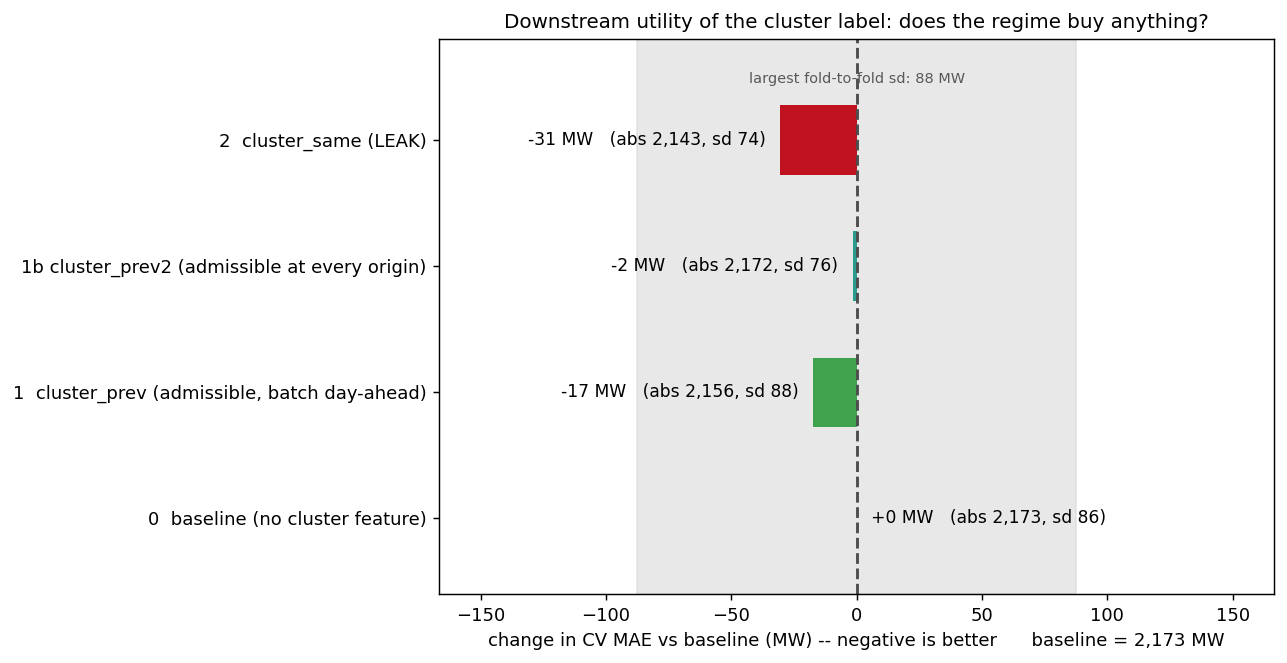


admissible (yesterday's regime, batch day-ahead):     -17.4 MW
admissible at every origin (the day before yesterday): -1.5 MW
leaked (today's own regime):                           -30.6 MW
largest fold sd across the arms:                        87.6 MW  <- one arm's fold spread; paired_p is the test
the leak is worth 13.2 MW of fake skill



wrote 6 files to C:\Users\alanm\OneDrive\Área de Trabalho\Grid Electricity MIlestone II FInal Project\data\processed\unsupervised
[results read-only] nb05: 9 key(s) verified against the ledger, nothing written


In [7]:
# WHAT: feed cluster membership back into the notebook 04 pipeline and measure the MAE
#       change -- under THREE framings, because one of them is a leak.
# WHY:  internal indices only say the clusters are tidy. An external task says
#       whether they carry information. But 5.5 as written in the plan is a trap,
#       and walking into it deliberately is the point of this cell.
#
# THE TRAP. `daily_shape_matrix` is built from `net_load` ITSELF -- 24 normalised
# hours of the target. So the cluster label for (zone, day d) is a summary of that
# day's actual net-load curve, INCLUDING the hour being forecast. Using it as a
# feature for a target inside the same day hands the model the shape of its own
# answer. It is not a subtle leak; it is the target, compressed to one integer.
#
# THE ADMISSIBLE VERSION is yesterday's regime. At a 24-hour origin the operator
# knows what shape yesterday had, so `cluster_prev` is ordinary history -- the same
# argument that makes wind_lag24 admissible while wind is not.
#
# All three arms are scored against one baseline, so the gaps are measured rather
# than asserted.
from src import models as X

lab = labels.reset_index()
lab.columns = [cfg.GROUP_COL, "date", "cluster"]
lab["date"] = pd.to_datetime(lab["date"])

hourly = df[[cfg.TIME_COL, cfg.GROUP_COL]].copy()
# THE JOIN MUST USE THE LOCAL CLOCK, the rule 5.4b already enforces for the weather.
# The labels are keyed by LOCAL date (daily_shape_matrix), so joining them onto the
# UTC date handed the first 4-8 hours of every UTC day the label of the wrong local
# day -- silently, because the merge succeeded and the row count was right. Measured
# with that defect: cluster_prev -42.7 MW and cluster_same -12.1 MW, the leaked arm
# inexplicably WORSE than the admissible one. The misalignment was the explanation.
hourly["date"] = P.local_calendar_date(hourly)

same = hourly.merge(lab, on=[cfg.GROUP_COL, "date"], how="left")
same_day = same[[cfg.TIME_COL, cfg.GROUP_COL]].assign(
    cluster_same=same["cluster"].astype("float"))

prev = lab.copy()
prev["date"] = prev["date"] + pd.Timedelta(days=1)   # yesterday's label, applied today
prev = hourly.merge(prev, on=[cfg.GROUP_COL, "date"], how="left")
prev_day = prev[[cfg.TIME_COL, cfg.GROUP_COL]].assign(
    cluster_prev=prev["cluster"].astype("float"))

# WHEN IS "YESTERDAY'S REGIME" ACTUALLY KNOWN? Only once yesterday is over. Under a
# rolling 24-hour origin the forecast for local hour H of day d is issued at hour H
# of day d-1, while day d-1 is still in progress -- so cluster_prev is admissible for
# a day-ahead forecast issued after 23:00 (the operator's batch run), not at every
# rolling origin. The label from two days back is complete at every origin, so it
# is scored as well: the arm that is admissible under BOTH framings.
prev2 = lab.copy()
prev2["date"] = prev2["date"] + pd.Timedelta(days=2)   # the day before yesterday
prev2 = hourly.merge(prev2, on=[cfg.GROUP_COL, "date"], how="left")
prev2_day = prev2[[cfg.TIME_COL, cfg.GROUP_COL]].assign(
    cluster_prev2=prev2["cluster"].astype("float"))

arms = {}
print("scoring three arms under identical folds, gap and estimator ...")
arms["0  baseline (no cluster feature)"] = X.score_with_extra_features(None)
arms["1  cluster_prev (admissible, batch day-ahead)"] = X.score_with_extra_features(prev_day)
arms["1b cluster_prev2 (admissible at every origin)"] = X.score_with_extra_features(prev2_day)
arms["2  cluster_same (LEAK)"] = X.score_with_extra_features(same_day)

base = arms["0  baseline (no cluster feature)"]["cv_mae_mean"]
# Each arm is scored on the same five folds as the baseline, so the difference is tested
# fold by fold (paired); `sd` is one arm's fold spread, mostly how hard each fold is.
from scipy import stats
_bf = np.asarray(arms["0  baseline (no cluster feature)"]["folds"])
util = pd.DataFrame([
    {"arm": k, "cv_mae": v["cv_mae_mean"], "sd": v["cv_mae_sd"],
     "delta_vs_baseline": v["cv_mae_mean"] - base,
     "paired_sd": float(np.std(np.asarray(v["folds"]) - _bf, ddof=1)),
     "paired_p": (float(stats.ttest_rel(np.asarray(v["folds"]), _bf).pvalue)
                  if not k.startswith("0") else float("nan"))}
    for k, v in arms.items()
]).round({"cv_mae": 1, "sd": 1, "delta_vs_baseline": 1, "paired_sd": 1, "paired_p": 3})
display(util)

fig, ax = plt.subplots(figsize=(10.0, 5.2))
colours = ["0.45", "#3fa34d", "#2a9d8f", "#c1121f"]
# THE NOISE FLOOR IS DRAWN, not left to the sd column: a bar inside the grey band is a
# difference one arm's fold spread cannot resolve; paired_p tests each arm against the baseline.
_sd_max = float(util["sd"].max())
ax.axvspan(-_sd_max, _sd_max, color="0.85", alpha=0.6, zorder=0)
ax.annotate(f"largest fold-to-fold sd: {_sd_max:,.0f} MW", (0, len(util) - 0.55), ha="center",
            fontsize=8, color="0.35")
# PLOT THE DIFFERENCE, NOT THE LEVEL. From a zero baseline these three bars were
# indistinguishable and the whole result sat in the annotations.
_d = util["delta_vs_baseline"].to_numpy(dtype=float)
ax.barh(util["arm"], _d, color=colours, height=0.55)
ax.axvline(0, ls="--", lw=1.6, color="0.3")
for y, (v, dlt, sd) in enumerate(zip(util["cv_mae"], _d, util["sd"])):
    ax.annotate(f"{dlt:+,.0f} MW   (abs {v:,.0f}, sd {sd:,.0f})", (dlt, y),
                xytext=(8 if dlt >= 0 else -8, 0), textcoords="offset points",
                va="center", ha="left" if dlt >= 0 else "right", fontsize=9.5)
ax.set_xlabel(f"change in CV MAE vs baseline (MW) -- negative is better"
              f"      baseline = {base:,.0f} MW")
ax.set_title("Downstream utility of the cluster label: "
             "does the regime buy anything?", fontsize=11)
_pad = max(float(np.abs(_d).max()), _sd_max, 1.0) * 1.9
ax.set_xlim(-_pad, _pad)
ax.set_ylim(-0.6, len(util) - 0.2)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "05_downstream_utility.png", bbox_inches="tight")
plt.show()

d_prev = arms["1  cluster_prev (admissible, batch day-ahead)"]["cv_mae_mean"] - base
d_prev2 = arms["1b cluster_prev2 (admissible at every origin)"]["cv_mae_mean"] - base
d_same = arms["2  cluster_same (LEAK)"]["cv_mae_mean"] - base
print(f"\nadmissible (yesterday's regime, batch day-ahead):     {d_prev:+,.1f} MW")
print(f"admissible at every origin (the day before yesterday): {d_prev2:+,.1f} MW")
print(f"leaked (today's own regime):                           {d_same:+,.1f} MW")
print(f"largest fold sd across the arms:                        {util['sd'].max():,.1f} MW"
      f"  <- one arm's fold spread; paired_p is the test")
_fake = d_prev - d_same          # > 0 : MAE the admissible arm could NOT reach
if _fake > 0:
    print(f"the leak is worth {_fake:,.1f} MW of fake skill")
else:
    print(f"the leak bought NOTHING -- it is {abs(_fake):,.1f} MW WORSE than the")
    print("admissible arm, and that is the measured result, not a bug. Each day is")
    print("normalised to [0,1] by daily_shape_matrix, so the cluster label carries")
    print("the day's SHAPE and not its LEVEL. MAE is dominated by level, and the lag")
    print("features already carry both. One integer of shape, added to twenty-odd")
    print("lags, has almost nothing left to contribute.")

# --- save the processed artefacts ---------------------------------------------
OUT = cfg.DATA_PROC / "unsupervised"
OUT.mkdir(parents=True, exist_ok=True)
shapes.reset_index().to_parquet(OUT / "daily_shapes.parquet", index=False)
lab.to_parquet(OUT / "cluster_labels.parquet", index=False)
grid.to_parquet(OUT / "clustering_grid.parquet", index=False)
same_day.to_parquet(OUT / "cluster_feature_same_day.parquet", index=False)
prev_day.to_parquet(OUT / "cluster_feature_prev_day.parquet", index=False)
(OUT / "manifest.json").write_text(json.dumps({
    "built_by": "notebook 05",
    "panel_source": cfg.PANEL.name,
    "panel_crc32": X.panel_hash(),
    "n_zone_days": int(len(shapes)),
    "algorithm": str(best_cfg["algorithm"]),
    "n_components": int(best_cfg["n_components"]),
    "param": float(best_cfg["param"]),
    "n_clusters": int(labels.nunique()),
    "files": {
        "daily_shapes.parquet": "zone-day x 24 normalised hours; the clustering input",
        "cluster_labels.parquet": "zone, date, cluster -- the fitted partition",
        "clustering_grid.parquet": "every (n_components, algorithm, param) cell scored",
        "cluster_feature_same_day.parquet": "LEAKED feature: today's own regime",
        "cluster_feature_prev_day.parquet": "admissible feature: yesterday's regime",
    },
    "warning": ("daily_shapes is built from net_load, the TARGET. cluster_same_day "
                "therefore encodes the answer's own shape and must never be used as "
                "a feature. It is exported so the leak can be reproduced, not used."),
}, indent=2), encoding="utf-8")
print(f"\nwrote {len(list(OUT.glob('*')))} files to {OUT}")

R.save("nb05", {
    "downstream": {k: {kk: vv for kk, vv in v.items() if kk != "folds"}
                   for k, v in arms.items()},
    "downstream_baseline_cv_mae": float(base),
    "delta_cluster_prev_mw": float(d_prev),
    "delta_cluster_prev2_mw": float(d_prev2),
    "delta_cluster_same_leaked_mw": float(d_same),
    "leak_worth_mw": float(d_prev - d_same),
    "downstream_fold_sd_max_mw": float(util["sd"].max()),
    "downstream_paired": {r["arm"]: {"paired_sd_mw": float(r["paired_sd"]), "paired_p": float(r["paired_p"])}
                           for _, r in util.iterrows() if not r["arm"].startswith("0")},
    "labels_joined_on": "local calendar date (P.local_calendar_date)",
});


**What this shows:** The CV MAE change when the label is added: `cluster_prev` (yesterday, admissible for a batch day-ahead forecast), `cluster_prev2` (two days back, admissible at every rolling origin) and `cluster_same` (leak, kept as a control).

**What I see:** Baseline 2,173.2 MW; `cluster_prev` 2,155.8 MW (−17.4, p 0.030); `cluster_prev2` 2,171.7 MW (−1.5, p 0.788); `cluster_same` 2,142.6 MW (−30.6, p 0.009). The largest fold sd, 87.6 MW, exceeds every gap, but the paired sd is only 11.3–14.5 MW.

**What it means:** The ordering is as expected: the leak helps most, yesterday's label a little, the label two days back not measurably. Yesterday's label lowers CV MAE by 17.4 MW, under 1%. The label carries a day's shape, not its level, and MAE is dominated by level, which the lags already carry.

**What I do:** Report all three arms with sd and paired p, and keep the leak as a control. For a rolling-origin forecast the arm to quote is `cluster_prev2`. The stronger validation of the clustering is the within-zone temperature signature from §5.4b–5.4c.


In [8]:
print("notebook 05 complete")
print(f"  partition:  {best_cfg['algorithm']}, {labels.nunique()} clusters, "
      f"ARI stability {best_cfg['ari_stability']:.3f}")
print(f"  utility:    cluster_prev {d_prev:+,.1f} MW vs baseline {base:,.1f} MW")
print(f"  the leak:   cluster_same {d_same:+,.1f} MW -- not a result, a warning")


notebook 05 complete
  partition:  kmeans, 3 clusters, ARI stability 0.996
  utility:    cluster_prev -17.4 MW vs baseline 2,173.2 MW
  the leak:   cluster_same -30.6 MW -- not a result, a warning
